In [1]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, export_graphviz, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

plt.rcParams["figure.figsize"] = (10, 7)

### Part 1, Toy dataset. 

In [2]:
def create_df(frame, feature_list):
    out = frame.copy()
    dummies = pd.get_dummies(out[feature_list], dtype=int)
    return pd.concat([out.drop(columns=feature_list), dummies], axis=1)

In [3]:
features = ["Looks", "Alcoholic_beverage", "Eloquence", "Money_spent"]

In [4]:
train_raw = pd.DataFrame({
    "Looks": ["handsome", "handsome", "handsome", "repulsive", "repulsive", "repulsive", "handsome"],
    "Alcoholic_beverage": ["yes", "yes", "no", "no", "yes", "yes", "yes"],
    "Eloquence": ["high", "low", "average", "average", "low", "high", "average"],
    "Money_spent": ["lots", "little", "lots", "little", "lots", "lots", "lots"],
})

target_labels = ["+", "-", "+", "-", "-", "+", "+"]
y = pd.Series(LabelEncoder().fit_transform(target_labels), name="Will_go", index=train_raw.index)

df_train = create_df(train_raw.assign(Will_go=y), features)
df_train = df_train.drop(columns="Will_go")
df_train

,Looks_handsome,Looks_repulsive,Alcoholic_beverage_no,Alcoholic_beverage_yes,Eloquence_average,Eloquence_high,Eloquence_low,Money_spent_little,Money_spent_lots
0,1,0,0,1,0,1,0,0,1
1,1,0,0,1,0,0,1,1,0
2,1,0,1,0,1,0,0,0,1
3,0,1,1,0,1,0,0,1,0
4,0,1,0,1,0,0,1,0,1
5,0,1,0,1,0,1,0,0,1
6,1,0,0,1,1,0,0,0,1


In [5]:
test_raw = pd.DataFrame({
    "Looks": ["handsome", "handsome", "repulsive"],
    "Alcoholic_beverage": ["no", "yes", "yes"],
    "Eloquence": ["average", "high", "average"],
    "Money_spent": ["lots", "little", "lots"],
})
df_test = create_df(test_raw, features)
df_test

,Looks_handsome,Looks_repulsive,Alcoholic_beverage_no,Alcoholic_beverage_yes,Eloquence_average,Eloquence_high,Money_spent_little,Money_spent_lots
0,1,0,1,0,1,0,0,1
1,1,0,0,1,0,1,1,0
2,0,1,0,1,1,0,0,1


In [6]:
# Some feature values are present in train and absent in test and vice-versa.
common_features = sorted(set(df_train.columns) & set(df_test.columns))
df_train = df_train[common_features]
df_test = df_test[common_features]

print(df_train.shape)
print(y.value_counts().sort_index().to_dict()) # 0 = +, 1 = -

(7, 8)
{0: 4, 1: 3}


## Entropy and Information Gain for Decision Trees

In [7]:
def entropy(data):
    values = pd.Series(np.asarray(data).reshape(-1))
    probs = values.value_counts(normalize=True).to_numpy()

    return float(-(probs * np.log2(probs)).sum())

looks_handsome = df_train['Looks_handsome'].astype(bool)

S0 = entropy(y)
S1 = entropy(y.loc[looks_handsome])
S2 = entropy(y.loc[~looks_handsome])

information_gain = S0 - looks_handsome.mean() * S1 - (~looks_handsome).mean() * S2

print(S0, S1, S2, information_gain, sep='\n\n')

0.9852281360342515

0.8112781244591328

0.9182958340544896

0.12808527889139443


## Train the decision tree classifier

In [11]:
tree = DecisionTreeClassifier(max_depth = 2, random_state = 1)
tree.fit(df_train, y)

print(accuracy_score(y, tree.predict(df_train)))

0.8571428571428571


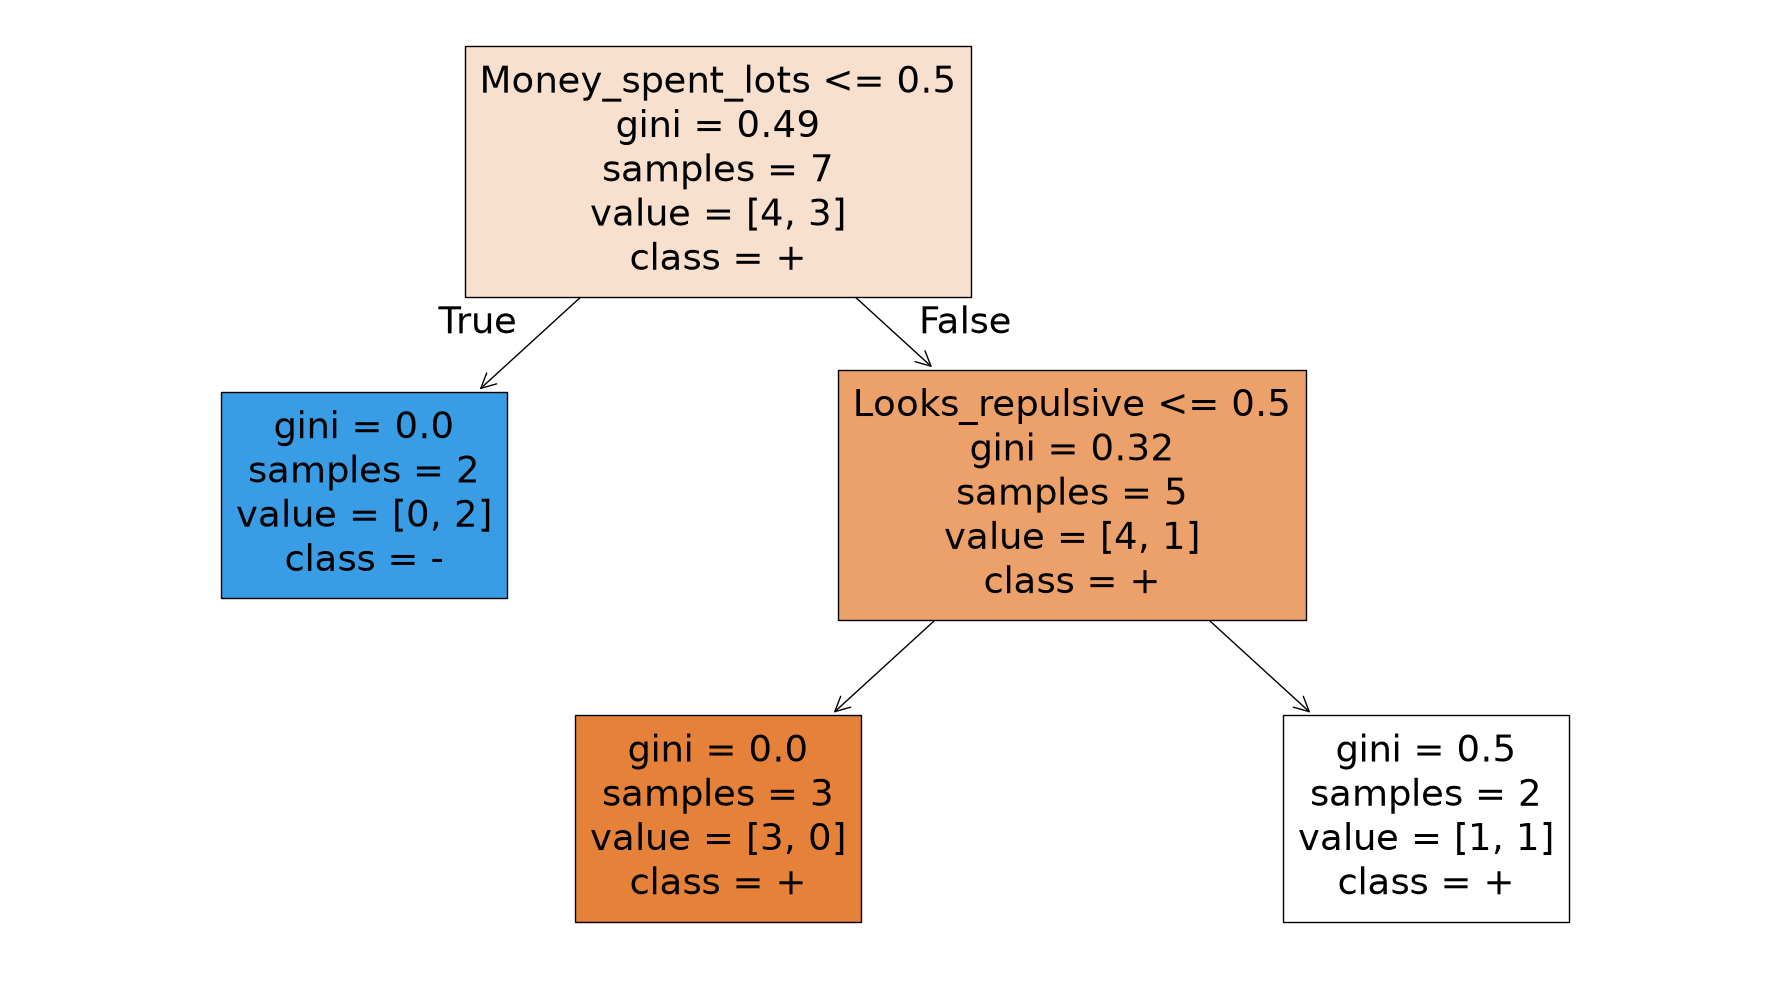

In [13]:
fig, ax = plt.subplots(figsize=(18, 10))
plot_tree(
    tree,
    feature_names=list(df_train.columns),
    class_names=["+", "-"],
    filled=True,
    ax=ax,
)
plt.tight_layout()
plt.show()

## Example on colored balls for entropy and information gain

In [14]:
balls = [1] * 9 + [0] * 11
balls_left = [1] * 8 + [0] * 5
balls_right = [1] * 1 + [0] * 6


print(entropy(balls), entropy(balls_left), entropy(balls_right), sep='\n\n')

0.9927744539878083

0.9612366047228759

0.5916727785823275


In [15]:
def information_gain(root, left, right):
    n = len(root)

    if len(left) + len(right) != n:
        raise ValueError('length issue')

    return float(entropy(root) - len(left) / n * entropy(left) - len(right) / n * entropy(right))

balls_ig = information_gain(balls, balls_left, balls_right)

print(balls_ig)

0.16088518841412436


#### time to do the information gains for every column of the dataset

In [17]:
def information_gains(X, y):
    y = pd.Series(np.asarray(y).reshape(-1), index = X.index)

    if len(y) != len(X):
        raise ValueError('length issue')

    igs = {}
    root_entropy = entropy(y)

    for column in X.columns:
        weighted_entropy = 0.0
        groups = X.groupby(column, sort=False, dropna=False).indices

        for positions in groups.values():
            group_y = y.iloc[positions]
            weighted_entropy += len(group_y) / len(y) * entropy(group_y)

        igs[column] = root_entropy - weighted_entropy

    return pd.Series(igs, name='information gain').sort_values(ascending=False)


toy_igs = information_gains(df_train, y)

display(toy_igs.to_frame())

,information gain
Money_spent_little,0.469565
Money_spent_lots,0.469565
Eloquence_high,0.291692
Looks_handsome,0.128085
Looks_repulsive,0.128085
Eloquence_average,0.020244
Alcoholic_beverage_no,0.005978
Alcoholic_beverage_yes,0.005978
